## Lab 3 

by Szymon Skrzypczyk

## Bayes and kNN classifiers

For this exercise I've used the Sentinel-2 images from lab 2, with forest from Puszcza Niepolomicka and urban areas from Krakow. Each pixel uses red and NIR values, forest is blue and urban is red. I've selected training patches and separate test crops from the same scenes, with visual labels for the evaluation patches


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

# Support running from the repository root or lab_3
helper_dir = Path("lab_3") if Path("lab_3/lab_helpers.py").is_file() else Path(".")
sys.path.insert(0, str(helper_dir))
from lab_helpers import load_scene, rgb_display, slices, colorize
from bayes_classifier import fit_bayes, gaussian_pdf, bayes_predict
from knn_classifier import knn_predict

SEED = 2026
AREAS = {0: "puszcza_niepolomicka", 1: "krakow"}
NAMES = {0: "Forest", 1: "Urban"}
COLORS = {0: "blue", 1: "red"}
BANDS = ("blue", "green", "red", "nir")

# Jupyter may start in the repository root or in lab_3
IMAGE_DIR = Path("lab_2/images")
if not IMAGE_DIR.is_dir():
    IMAGE_DIR = Path("../lab_2/images")
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError("Run the notebook from the repository root or lab_3")
print("Images:", IMAGE_DIR)

Images: ..\lab_2\images


In [2]:
scenes = {area: load_scene(area, IMAGE_DIR, BANDS) for area in AREAS.values()}

for scene in scenes.values():
    scene["rgb"] = rgb_display(scene)
    scene["features"] = scene["cube"][..., [2, 3]]  # red, NIR

## Selecting the areas

Both scenes contain different land covers, so I've selected small patches for each class. Solid rectangles mark training patches and dashed rectangles mark evaluation patches, with coordinates in rows and columns  The RGB stretch is only for display, while classification uses the original band values


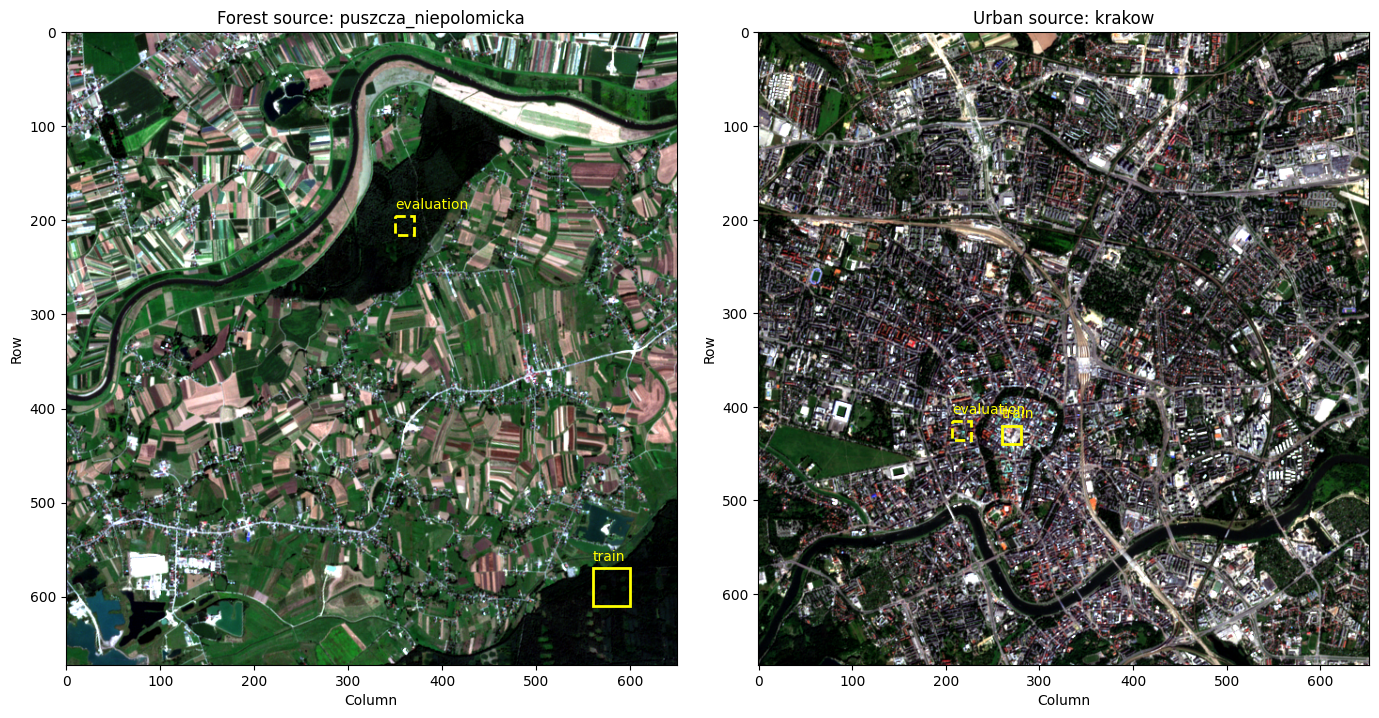

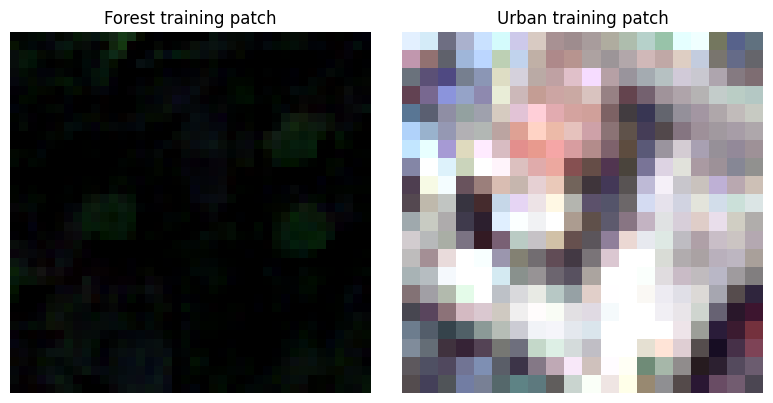

Training pixels per class: 400


In [3]:
TRAIN_ROIS = {
    0: (570, 610, 560, 600),
    1: (420, 440, 260, 280),
}
TEST_ROIS = {
    0: (195, 215, 350, 370),
    1: (415, 435, 207, 227),
}
TEST_CROPS = {
    0: (165, 245, 325, 405),
    1: (385, 465, 170, 250),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for label, ax in enumerate(axes):
    scene = scenes[AREAS[label]]
    ax.imshow(scene["rgb"])
    for box, style, text in (
        (TRAIN_ROIS[label], "-", "train"),
        (TEST_ROIS[label], "--", "evaluation"),
    ):
        r0, r1, c0, c1 = box
        ax.add_patch(Rectangle(
            (c0, r0), c1-c0, r1-r0, fill=False,
            edgecolor="yellow", linewidth=2, linestyle=style,
        ))
        ax.text(c0, r0-8, text, color="yellow", fontsize=10)
    ax.set_title(f"{NAMES[label]} source: {AREAS[label]}")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
plt.tight_layout()
plt.show()

# Use the same balanced training set for both classifiers.
rng = np.random.default_rng(SEED)
samples = []
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for label, ax in enumerate(axes):
    scene = scenes[AREAS[label]]
    sl = slices(TRAIN_ROIS[label])
    x = scene["features"][sl][scene["valid"][sl]]
    samples.append(x[rng.choice(len(x), 400, replace=False)])
    ax.imshow(scene["rgb"][sl])
    ax.set_title(f"{NAMES[label]} training patch")
    ax.axis("off")
plt.tight_layout()
plt.show()
n = min(map(len, samples))
X_train = np.vstack([x[:n] for x in samples])
y_train = np.repeat([0, 1], n)
print(f"Training pixels per class: {n}")

## Bayes classifier

I model each class with a two-dimensional Gaussian using red and NIR values. The mean and covariance come from the training pixels, and a small diagonal value keeps the covariance invertible

$$p(x\mid c)=\frac{\exp[-\frac12(x-\mu_c)^T\Sigma_c^{-1}(x-\mu_c)]}{2\pi\sqrt{|\Sigma_c|}}$$

The plots compare each band histogram with its fitted Gaussian  

Source: [Penn State, multivariate normal distribution](https://online.stat.psu.edu/stat505/Lesson04)



Forest: mean [red, NIR] = [ 185.69 2727.44]
Regularized covariance:
 [[   813.24   1735.58]
 [  1735.58 272099.99]]
Marginal standard deviations: [ 28.52 521.63]

Urban: mean [red, NIR] = [1381.13 1595.92]
Regularized covariance:
 [[190795.12 202739.13]
 [202739.13 276269.39]]
Marginal standard deviations: [436.8  525.61]


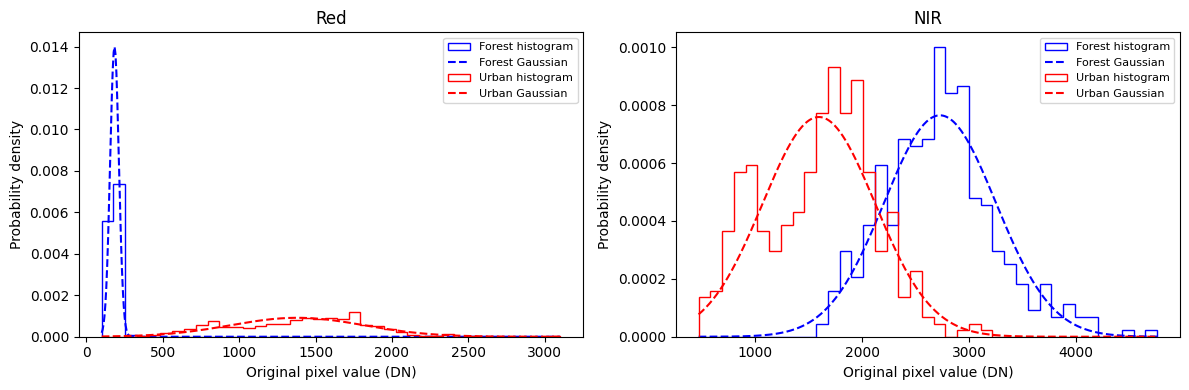

In [4]:
means, covariances = fit_bayes(X_train, y_train)
for label in (0, 1):
    print(f"\n{NAMES[label]}: mean [red, NIR] = {means[label].round(2)}")
    print("Regularized covariance:\n", covariances[label].round(2))
    print("Marginal standard deviations:", np.sqrt(np.diag(covariances[label])).round(2))

# Equal priors: the training sampling ratio is not a land-cover area estimate.
priors = np.array([0.5, 0.5])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, ax in enumerate(axes):
    values = X_train[:, j]
    bins = np.linspace(values.min(), values.max(), 40)
    grid = np.linspace(values.min(), values.max(), 500)
    for label in (0, 1):
        x = X_train[y_train == label, j]
        sigma = np.sqrt(covariances[label, j, j])
        pdf = gaussian_pdf(grid, means[label, j], sigma)
        ax.hist(x, bins=bins, density=True, histtype="step",
                color=COLORS[label], label=f"{NAMES[label]} histogram")
        ax.plot(grid, pdf, color=COLORS[label], linestyle="--",
                label=f"{NAMES[label]} Gaussian")
    ax.set(title=("Red", "NIR")[j], xlabel="Original pixel value (DN)",
           ylabel="Probability density")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The difference between the classes is quite visible for both `red` and `nir` bands, for `nir` forest tends to have higher pixel values, while for `red` it's quite the opposite and the difference is significant. As such I believe that these two bands (their combination) is perfect for detecting both classes in this exercise

## Bayes decision

For each pixel I compare the Gaussian likelihood and prior for both classes, then select the larger score  I use equal priors and equal error costs, with logarithms to keep the calculation stable

$$\hat c=\arg\max_c[\log p(x\mid c)+\log P(c)]$$

The test image joins two crops from the same scenes, without overlap with the training patches  Only the two visually labeled patches are used for accuracy, and gray in the reference map means unlabeled  Source: [Penn State, Bayes rule and classification](https://online.stat.psu.edu/stat857/node/17/)


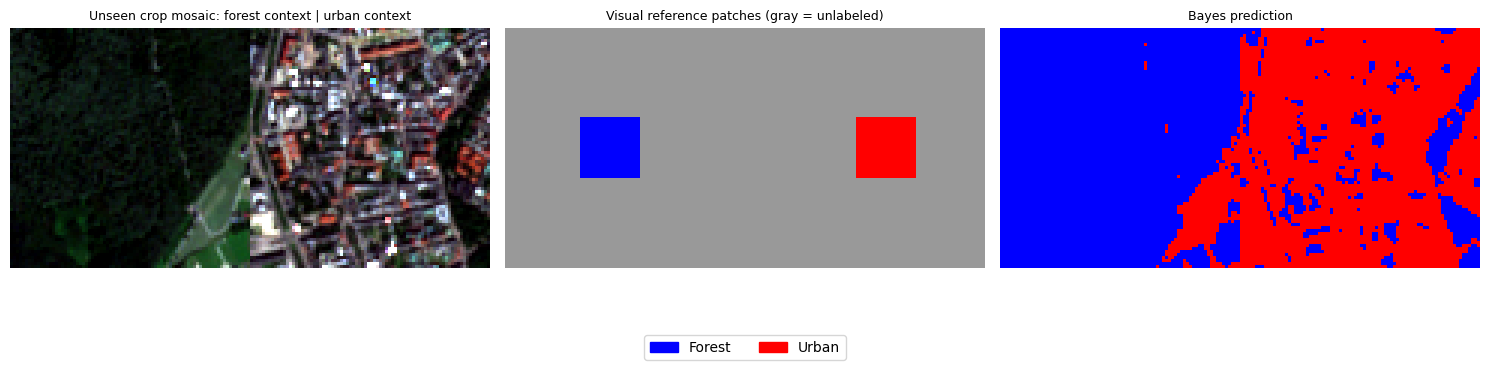

In [5]:
def to_map(predictions):
    result = np.full(new_valid.shape, -1, dtype=np.int8)
    result[new_valid] = predictions
    return result

# Build an unseen image from two non-overlapping held-out contexts.
feature_parts, rgb_parts, valid_parts, truth_parts = [], [], [], []
for label in (0, 1):
    scene = scenes[AREAS[label]]
    box = TEST_CROPS[label]
    sl = slices(box)
    feature_parts.append(scene["features"][sl])
    rgb_parts.append(scene["rgb"][sl])
    valid_parts.append(scene["valid"][sl])
    truth = np.full(scene["valid"][sl].shape, -1, dtype=np.int8)
    r0, r1, c0, c1 = TEST_ROIS[label]
    truth[r0-box[0]:r1-box[0], c0-box[2]:c1-box[2]] = label
    truth_parts.append(truth)

new_features = np.concatenate(feature_parts, axis=1)
new_rgb = np.concatenate(rgb_parts, axis=1)
new_valid = np.concatenate(valid_parts, axis=1)
y_reference = np.concatenate(truth_parts, axis=1)
X_new = new_features[new_valid]
evaluation_mask = new_valid & (y_reference >= 0)

bayes_map = to_map(bayes_predict(X_new, means, covariances, priors))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, img, title in zip(
    axes,
    (new_rgb, colorize(y_reference), colorize(bayes_map)),
    ("Unseen crop mosaic: forest context | urban context",
     "Visual reference patches (gray = unlabeled)", "Bayes prediction"),
):
    ax.imshow(img, interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.legend(handles=[Patch(color="blue", label="Forest"),
                    Patch(color="red", label="Urban")], loc="lower center", ncol=2)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

It can be seen that the forest areas are correctly selected as `Forest` class, but other areas including meadow and paths in the forest are assigned to urban class, I believe it's due to large differences in the characteristics of two classes, which is clearly visible on the histograms

## kNN classifier

I've used the same training pixels and bands as Bayes. First I standardize both training and test pixels using the training mean and standard deviation, then calculate squared Euclidean distances and assign the majority class among the k nearest training pixels. I've tested k = 1, 3 and 5, and processed pixels in batches to limit memory use (just in case it's an issue :))


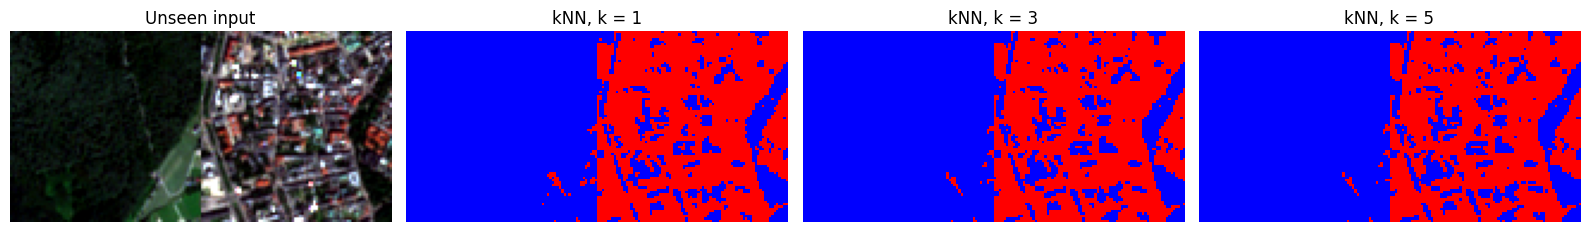

In [6]:
knn_predictions = knn_predict(X_train, y_train, X_new, seed=SEED)
knn_maps = {k: to_map(pred) for k, pred in knn_predictions.items()}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(new_rgb)
axes[0].set_title("Unseen input")
for ax, k in zip(axes[1:], (1, 3, 5)):
    ax.imshow(colorize(knn_maps[k]), interpolation="nearest")
    ax.set_title(f"kNN, k = {k}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [7]:
# Scores use only the visually labeled evaluation patches, never training pixels.
def evaluate(label_map):
    actual = y_reference[evaluation_mask]
    predicted = label_map[evaluation_mask]
    cm = np.zeros((2, 2), dtype=int)
    np.add.at(cm, (actual, predicted), 1)
    recall = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
    return {
        "cm": cm,
        "accuracy": np.trace(cm) / cm.sum(),
        "balanced_accuracy": recall.mean(),
        "recall": recall,
    }


maps = {"Bayes": bayes_map, **{f"kNN k={k}": knn_maps[k] for k in (1, 3, 5)}}
results = {name: evaluate(label_map) for name, label_map in maps.items()}
print("Reference patches, rows = actual, columns = predicted")
print("Class order: Forest, Urban\n")
print(f"{'Model':<12} {'Accuracy':>10} {'Balanced':>10} {'Forest recall':>15} {'Urban recall':>14}")
for name, result in results.items():
    print(f"{name:<12} {result['accuracy']:>10.3f} {result['balanced_accuracy']:>10.3f} "
          f"{result['recall'][0]:>15.3f} {result['recall'][1]:>14.3f}")
    print("Confusion matrix:", result["cm"].tolist())


Reference patches, rows = actual, columns = predicted
Class order: Forest, Urban

Model          Accuracy   Balanced   Forest recall   Urban recall
Bayes             0.929      0.929           1.000          0.858
Confusion matrix: [[400, 0], [57, 343]]
kNN k=1           0.890      0.890           1.000          0.780
Confusion matrix: [[400, 0], [88, 312]]
kNN k=3           0.879      0.879           1.000          0.757
Confusion matrix: [[400, 0], [97, 303]]
kNN k=5           0.871      0.871           1.000          0.743
Confusion matrix: [[400, 0], [103, 297]]
k=1 vs k=3: 1.35% changed
k=3 vs k=5: 0.73% changed
k=1 vs k=5: 2.08% changed


In [8]:
best_score = max(results[f"kNN k={k}"]["balanced_accuracy"] for k in (1, 3, 5))
best_ks = [k for k in (1, 3, 5)
           if np.isclose(results[f"kNN k={k}"]["balanced_accuracy"], best_score)]
print(f"Best k: {best_ks}, balanced accuracy: {best_score:.3f}")

Best k: [1], balanced accuracy: 0.890


It's quite interesting to see, even though that visually different k centroids did not massively impact the results in the details those mattered and `k = 1` turned out to be the most accurate one in this particular case. It's worth noting that Bayes' classifier had a better accuracy

## Results

On the visually labeled patches Bayes reaches 92.9% accuracy, while kNN reaches 89.0%, 87.9% and 87.1% for k = 1, 3 and 5. All models classify the forest reference patch correctly, with the errors coming from urban pixels labeled as forest. The red band separates the selected classes more clearly than NIR, although the Gaussian curves miss some peaks and tails

Increasing `k` reduces the influence of individual training pixels, but accuracy falls on these patches and k = 1 performs best  The maps change for `1.35%` of valid pixels between `k = 1` and `3`, and `0.73%` between `k = 3` and `5`

These scores cover 800 visually labeled pixels, not the full mosaic. The crops come from the training scenes, so the scores do not measure performance on a separate satellite image  Other land covers in the mosaic still receive one of the two labels

I believe that even though the accuracy is quite sufficient (I find acc of about 90% to be satisfactory), there are areas to improve - another class would help with confussing crops/meadow as urban or possibly more training data would help with that, but as a very basic classification, the created classifiers have demonstrated that they are able to distinguish the dependencies and tell the classes apart

## Extra cases

I've selected two more crops from the same scenes to compare the classifiers on new pixels  These crops are separate from the training and reference patches  I show predictions for Bayes and kNN with k = 1, 3 and 5  The crops have no reference labels, so the results are a visual comparison


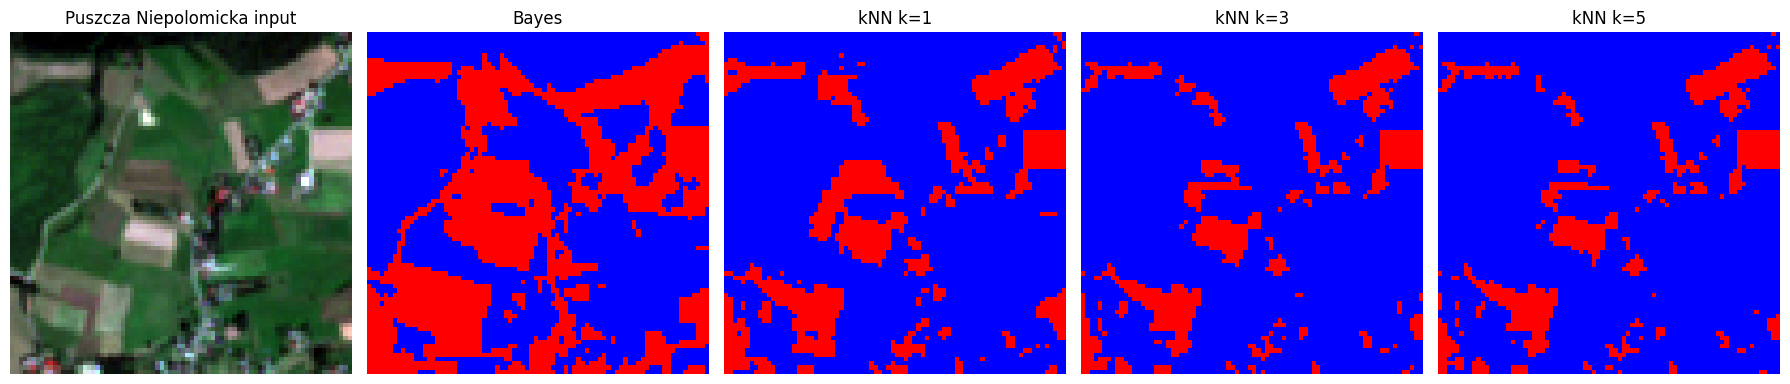

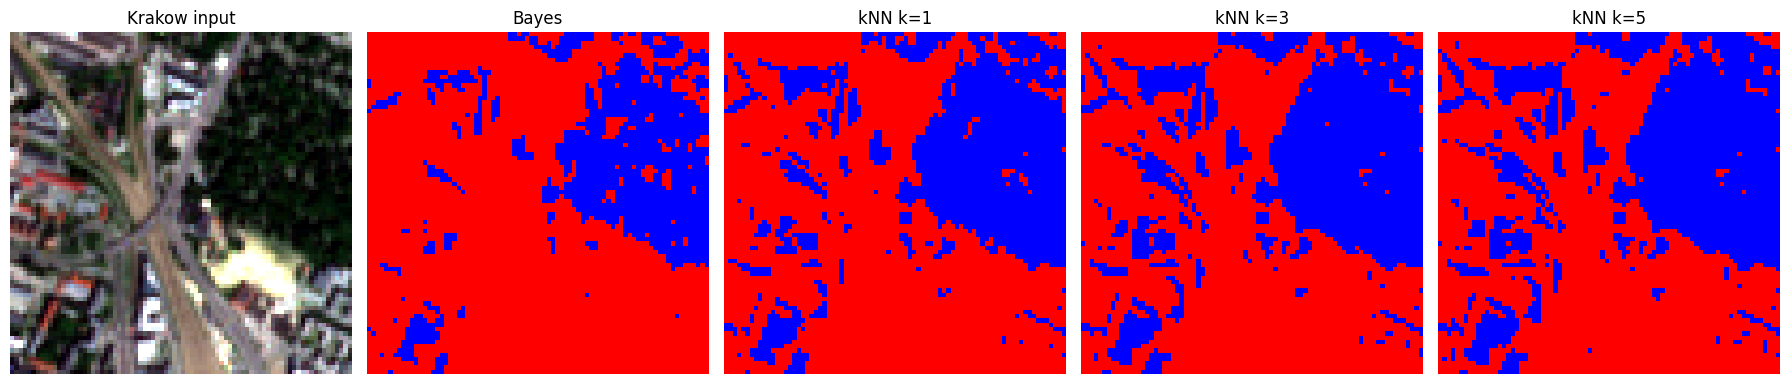

In [9]:
extra_cases = {
    "Puszcza Niepolomicka": (0, (280, 360, 250, 330)),
    "Krakow": (1, (250, 330, 300, 380)),
}

for name, (label, box) in extra_cases.items():
    scene = scenes[AREAS[label]]
    area = slices(box)
    valid = scene["valid"][area]
    pixels = scene["features"][area][valid]

    predictions = {"Bayes": bayes_predict(pixels, means, covariances, priors)}
    knn = knn_predict(X_train, y_train, pixels, seed=SEED)
    predictions.update({f"kNN k={k}": knn[k] for k in (1, 3, 5)})

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    axes[0].imshow(scene["rgb"][area])
    axes[0].set_title(f"{name} input")
    for ax, (title, labels) in zip(axes[1:], predictions.items()):
        result = np.full(valid.shape, -1, dtype=np.int8)
        result[valid] = labels
        ax.imshow(colorize(result), interpolation="nearest")
        ax.set_title(title)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


For the first scene the difference between Bayes' and kNN is quite significant, again areas that were not clearly marked as forest or urban are where the model gets 'confused'